# Embedding-Based WSD Classifier

Train MLP classifiers on contextual embeddings to predict word senses (using LLM labels as ground truth).

**Data**: `passio_sample1000_classified.parquet`, `pathos_sample1000_classified.parquet`

**Embeddings tested**:
- LaBERT WSD (layers 7, 11)
- PhilBerta (layers 7, 11)

**Labels**: `class_llama3.3` (LLM-based sense classifications)

In [64]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix

# Helper modules are in the same directory
import classification_helpers

## Load Data

In [65]:
passio_df = pd.read_parquet("../data/large_files/passio_sample2000_classified_embeddings.parquet")
pathos_df = pd.read_parquet("../data/large_files/pathos_sample2000_classified_embeddings.parquet")

print(f"Passio: {len(passio_df)} rows")
print(f"Pathos: {len(pathos_df)} rows")

Passio: 2000 rows
Pathos: 2000 rows


In [66]:
pathos_df.columns

Index(['target_phrase', 'target_from', 'matched_by', 'target_lemmata',
       'target_token_ids', 'target_kwic_idx', 'target_sent_idx', 'grela_id',
       'target_sentence_id', 'start_sentence_id', 'end_sentence_id',
       'kwic_text', 'kwic_tokens', 'target_sentence_text',
       'target_sentence_tokens', 'author', 'title', 'not_before', 'not_after',
       'emb_labert_wsd_l7', 'emb_labert_wsd_l11', 'emb_philberta_l7',
       'emb_philberta_l11', 'passage', 'class_qwen3.8:27b', 'emb_xlmr_l7',
       'emb_xlmr_l11', 'emb_mdeberta_l7', 'emb_mdeberta_l11',
       'emb_mdeberta_l6', 'emb_mdeberta_l8', 'emb_mdeberta_l9',
       'emb_mdeberta_l10'],
      dtype='str')

## Label Distributions

In [67]:
model = "qwen3.8:27b"

print(f"=== PASSIO - class_{model} ===")
print(passio_df[f"class_{model}"].value_counts().sort_index())

print(f"Unique classes: {passio_df[f'class_{model}'].nunique()}")

=== PASSIO - class_qwen3.8:27b ===
class_qwen3.8:27b
0    222
1    160
2    387
3    827
4     58
5    346
Name: count, dtype: int64
Unique classes: 6


In [68]:
print(f"=== PATHOS - class_{model} ===")
print(pathos_df[f"class_{model}"].value_counts().sort_index())
print(f"\nUnique classes: {pathos_df[f'class_{model}'].nunique()}")

=== PATHOS - class_qwen3.8:27b ===
class_qwen3.8:27b
0    417
1    455
2    678
3    450
Name: count, dtype: int64

Unique classes: 4


## Define Embedding Columns to Test

In [69]:
EMB_COLS = [col for col in passio_df.columns if col.startswith("emb_")]
EMB_COLS

['emb_labert_wsd_l7',
 'emb_labert_wsd_l11',
 'emb_philberta_l7',
 'emb_philberta_l11',
 'emb_xlmr_l7',
 'emb_xlmr_l11',
 'emb_mdeberta_l7',
 'emb_mdeberta_l11',
 'emb_mdeberta_l6',
 'emb_mdeberta_l8',
 'emb_mdeberta_l9',
 'emb_mdeberta_l10']

In [70]:

LABEL_COL = f"class_{model}"

# Filter out rows with NaN labels (passio has 1 such row)
print(f"Passio NaN labels before filtering: {passio_df[LABEL_COL].isna().sum()}")
print(f"Pathos NaN labels before filtering: {pathos_df[LABEL_COL].isna().sum()}")

passio_df = passio_df.dropna(subset=[LABEL_COL])
pathos_df = pathos_df.dropna(subset=[LABEL_COL])

print(f"Passio rows after filtering: {len(passio_df)}")
print(f"Pathos rows after filtering: {len(pathos_df)}")

Passio NaN labels before filtering: 0
Pathos NaN labels before filtering: 0
Passio rows after filtering: 2000
Pathos rows after filtering: 2000


## Evaluation Function

In [71]:
def evaluate_embedding_model(df, emb_col, label_col=LABEL_COL, cv=5):
    """Evaluate MLP classifier on a single embedding column."""
    X, y = classification_helpers.prepare_classification_data(df, emb_col, label_col)
    clf = classification_helpers.create_mlp_classifier()
    result = classification_helpers.evaluate_classifier(X, y, clf, cv=cv)
    return result

## Evaluate All Embedding Models (Passio)

In [72]:
passio_results = {}

for emb_col in EMB_COLS:
    print(f"Evaluating {emb_col}...")
    result = evaluate_embedding_model(passio_df, emb_col)
    passio_results[emb_col] = result
    print(f"  Accuracy: {result['accuracy']:.4f}")
    print(f"  F1 Macro: {result['f1_macro']:.4f}")
    print()

Evaluating emb_labert_wsd_l7...
  Accuracy: 0.6505
  F1 Macro: 0.5419

Evaluating emb_labert_wsd_l11...
  Accuracy: 0.7450
  F1 Macro: 0.6635

Evaluating emb_philberta_l7...
  Accuracy: 0.6735
  F1 Macro: 0.5871

Evaluating emb_philberta_l11...
  Accuracy: 0.7320
  F1 Macro: 0.6523

Evaluating emb_xlmr_l7...
  Accuracy: 0.7060
  F1 Macro: 0.6237

Evaluating emb_xlmr_l11...
  Accuracy: 0.7425
  F1 Macro: 0.6704

Evaluating emb_mdeberta_l7...
  Accuracy: 0.7855
  F1 Macro: 0.7199

Evaluating emb_mdeberta_l11...
  Accuracy: 0.7510
  F1 Macro: 0.6724

Evaluating emb_mdeberta_l6...
  Accuracy: 0.7540
  F1 Macro: 0.6825

Evaluating emb_mdeberta_l8...
  Accuracy: 0.7880
  F1 Macro: 0.7332

Evaluating emb_mdeberta_l9...
  Accuracy: 0.7935
  F1 Macro: 0.7402

Evaluating emb_mdeberta_l10...
  Accuracy: 0.7760
  F1 Macro: 0.7138



In [73]:
passio_results_df = pd.DataFrame([
    {
        "embedding": emb_col,
        "accuracy": result["accuracy"],
        "f1_macro": result["f1_macro"]
    }
    for emb_col, result in passio_results.items()
])

passio_results_df.to_markdown(index=False)

'| embedding          |   accuracy |   f1_macro |\n|:-------------------|-----------:|-----------:|\n| emb_labert_wsd_l7  |     0.6505 |   0.541873 |\n| emb_labert_wsd_l11 |     0.745  |   0.663548 |\n| emb_philberta_l7   |     0.6735 |   0.587127 |\n| emb_philberta_l11  |     0.732  |   0.652289 |\n| emb_xlmr_l7        |     0.706  |   0.623703 |\n| emb_xlmr_l11       |     0.7425 |   0.670448 |\n| emb_mdeberta_l7    |     0.7855 |   0.719928 |\n| emb_mdeberta_l11   |     0.751  |   0.672446 |\n| emb_mdeberta_l6    |     0.754  |   0.682485 |\n| emb_mdeberta_l8    |     0.788  |   0.733249 |\n| emb_mdeberta_l9    |     0.7935 |   0.740173 |\n| emb_mdeberta_l10   |     0.776  |   0.713754 |'

## Evaluate All Embedding Models (Pathos)

In [ ]:
pathos_results = {}

for emb_col in EMB_COLS:
    print(f"Evaluating {emb_col}...")
    result = evaluate_embedding_model(pathos_df, emb_col)
    pathos_results[emb_col] = result
    print(f"  Accuracy: {result['accuracy']:.4f}")
    print(f"  F1 Macro: {result['f1_macro']:.4f}")
    print()

Evaluating emb_labert_wsd_l7...
  Accuracy: 0.3675
  F1 Macro: 0.3505

Evaluating emb_labert_wsd_l11...
  Accuracy: 0.3885
  F1 Macro: 0.3695

Evaluating emb_philberta_l7...


In [46]:
pathos_results_df = pd.DataFrame([
    {
        "embedding": emb_col,
        "accuracy": result["accuracy"],
        "f1_macro": result["f1_macro"]
    }
    for emb_col, result in pathos_results.items()
])

pathos_results_df.to_markdown(index=False)

'| embedding          |   accuracy |   f1_macro |\n|:-------------------|-----------:|-----------:|\n| emb_labert_wsd_l7  |     0.3675 |   0.350475 |\n| emb_labert_wsd_l11 |     0.3885 |   0.369488 |\n| emb_philberta_l7   |     0.57   |   0.550275 |\n| emb_philberta_l11  |     0.633  |   0.62018  |\n| emb_xlmr_l7        |     0.5065 |   0.492907 |\n| emb_xlmr_l11       |     0.5335 |   0.523863 |\n| emb_mdeberta_l7    |     0.642  |   0.632128 |\n| emb_mdeberta_l11   |     0.5945 |   0.583545 |'

## Compare Results Visualization

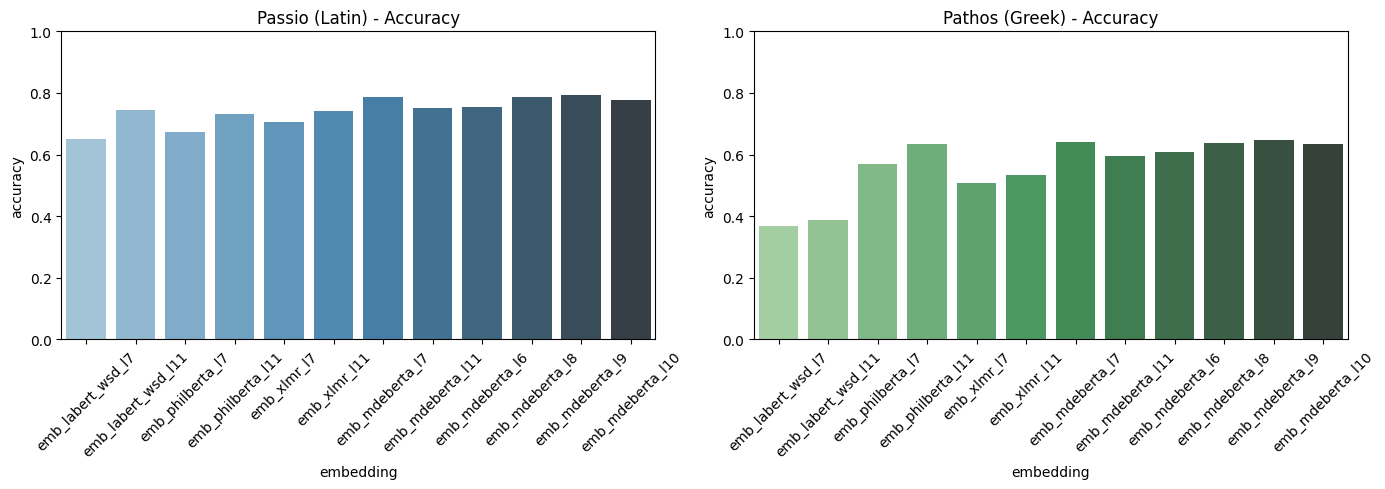

In [81]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Passio
sns.barplot(
    data=passio_results_df,
    x="embedding",
    y="accuracy",
    ax=axes[0],
    palette="Blues_d"
)
axes[0].set_title("Passio (Latin) - Accuracy")
axes[0].tick_params(axis='x', rotation=45)
axes[0].set_ylim(0, 1)

# Pathos
sns.barplot(
    data=pathos_results_df,
    x="embedding",
    y="accuracy",
    ax=axes[1],
    palette="Greens_d"
)
axes[1].set_title("Pathos (Greek) - Accuracy")
axes[1].tick_params(axis='x', rotation=45)
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.savefig("../figures/embedding-classifier-comparison.png", dpi=150, bbox_inches='tight')
plt.show()

## Merged Embeddings Experiment

In [89]:
# Test merging top embeddings from both models (layer 11)
X_merged = classification_helpers.merge_multiple_embeddings(
    passio_df, 
    ["emb_philberta_l11", "emb_mdeberta_l9"], 
    method="concat"
)
print(f"Merged embedding shape: {X_merged.shape}")

# Evaluate merged embeddings
y = passio_df[LABEL_COL].values
clf_merged = classification_helpers.create_mlp_classifier()
result_merged = classification_helpers.evaluate_classifier(X_merged, y, clf_merged, cv=5)
print(f"Merged (concat) - Accuracy: {result_merged['accuracy']:.4f}, F1: {result_merged['f1_macro']:.4f}")

Merged embedding shape: (2000, 1536)


In [90]:
# Test merging top embeddings from both models (layer 11)
X_merged = classification_helpers.merge_multiple_embeddings(
    pathos_df, 
    ["emb_philberta_l11", "emb_mdeberta_l9"], 
    method="concat"
)
print(f"Merged embedding shape: {X_merged.shape}")

# Evaluate merged embeddings
y = pathos_df[LABEL_COL].values
clf_merged = classification_helpers.create_mlp_classifier()
result_merged = classification_helpers.evaluate_classifier(X_merged, y, clf_merged, cv=5)
print(f"Merged (concat) - Accuracy: {result_merged['accuracy']:.4f}, F1: {result_merged['f1_macro']:.4f}")

Merged embedding shape: (2000, 1536)
Merged (concat) - Accuracy: 0.6970, F1: 0.6853


In [93]:
import joblib
import importlib
from pathlib import Path

EMBEDDING_COLS = ["emb_philberta_l11", "emb_mdeberta_l9"]
MODEL_DIR = Path("../data")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

for lexeme, df in [
    ("passio", passio_df),
    ("pathos", pathos_df),
]:
    X = classification_helpers.merge_multiple_embeddings(
        df, EMBEDDING_COLS, method="concat"
    )
    y = df[LABEL_COL].to_numpy()

    result = classification_helpers.evaluate_classifier(
        X, y,
        classification_helpers.create_mlp_classifier(),
        cv=5,
        return_model=True,
    )

    prompt_module = importlib.import_module(f"llmprompt_{lexeme}")
    importlib.reload(prompt_module)

    # Store the preprocessing/model pipeline and its input specification.
    artifact = {
        "model": result["model"],
        "embedding_cols": EMBEDDING_COLS.copy(),
        "merge_method": "concat",
        "label_column": LABEL_COL,
        "label_map": dict(prompt_module.LABEL_MAP),
        "cv_accuracy": result["accuracy"],
        "cv_f1_macro": result["f1_macro"],
    }

    path = MODEL_DIR / f"{lexeme}_wsd_philberta_l11_mdeberta_l9_concat.joblib"
    joblib.dump(artifact, path)
    print(f"Saved {path}")

Saved ../data/passio_wsd_philberta_l11_mdeberta_l9_concat.joblib
Saved ../data/pathos_wsd_philberta_l11_mdeberta_l9_concat.joblib


## Confusion matrices by embedding

Adapted from the row-normalized heatmap grids in the earlier *labyrinthus*
[classification evaluation notebook](https://github.com/CCS-ZCU/labyrinth/blob/master/scripts/6_labyrinth_classification-evaluations.ipynb).
Reuses the evaluation results' out-of-fold predictions. Sense names are loaded
and reloaded from `llmprompt_passio.py` / `llmprompt_pathos.py` at plotting time.
Rows represent annotated senses, columns predicted senses; normalized rows sum
to one (unobserved senses have zero rows). Keep the evaluation dataframe's row
order unchanged; rerun evaluation if the annotation data change.


In [87]:
import importlib
import textwrap


def plot_embedding_confusion_matrices(
    df, results, lexeme, label_col, embedding_cols=None, top_n=4,
    normalize="true", ncols=2,
):
    """Plot cached out-of-fold predictions; no embeddings or models are recomputed.

    By default show the top four embeddings by macro-F1. Supply embedding_cols
    for a particular comparison, or top_n=None for all evaluated embeddings.
    normalize='true' shows recall by sense; None shows raw counts.
    Sense names are reloaded from llmprompt_<lexeme>.LABEL_MAP on every call.
    df must retain the row order and labels used to generate results.
    """
    from sklearn.metrics import confusion_matrix

    prompt_module = importlib.import_module(f"llmprompt_{lexeme}")
    label_map = dict(importlib.reload(prompt_module).LABEL_MAP)
    raw_labels = df[label_col]
    if raw_labels.isna().any():
        raise ValueError("Use the same filtered dataframe as in evaluation (no missing labels).")
    if normalize not in (None, "true", "pred", "all"):
        raise ValueError("normalize must be None, 'true', 'pred', or 'all'.")
    if ncols < 1 or (top_n is not None and top_n < 1):
        raise ValueError("ncols and top_n must be positive.")

    # Mirror prepare_classification_data's first-seen encoding for object dtype.
    # Encoded prediction IDs may differ from the original inventory IDs.
    if raw_labels.dtype == object:
        original_labels = raw_labels.unique()
        encoded = {label: i for i, label in enumerate(original_labels)}
        y_true = np.array([encoded[label] for label in raw_labels])
        display_map = {}
        for i, label in enumerate(original_labels):
            name = label_map.get(label)
            if name is None and isinstance(label, str) and label.isdigit():
                name = label_map.get(int(label))
            display_map[i] = str(name if name is not None else label)
    elif pd.api.types.is_numeric_dtype(raw_labels.dtype):
        y_true = raw_labels.to_numpy()
        display_map = {label: str(name) for label, name in label_map.items()}
        for label in np.unique(y_true):
            display_map.setdefault(label, str(label))

    else:
        # Pandas StringDtype is not object: the evaluation helper keeps strings.
        y_true = raw_labels.to_numpy()
        display_map = {}
        for label in raw_labels.unique():
            key = int(label) if isinstance(label, str) and label.isdigit() else label
            display_map[label] = str(label_map.get(key, label))

    labels = sorted(display_map)
    names = [textwrap.fill(display_map[label].replace("_", " "), width=22)
             for label in labels]
    if embedding_cols is None:
        embedding_cols = sorted(results, key=lambda col: results[col]["f1_macro"], reverse=True)
        if top_n is not None:
            embedding_cols = embedding_cols[:top_n]
    else:
        embedding_cols = list(embedding_cols)
    if not embedding_cols:
        raise ValueError("No evaluated embeddings selected.")

    # Validate all predictions before creating a figure; never silently drop IDs.
    for col in embedding_cols:
        prediction = np.asarray(results[col]["predictions"])
        if prediction.ndim != 1 or len(prediction) != len(y_true):
            raise ValueError(f"{col}: predictions are not aligned with dataframe rows.")
        unknown = set(np.unique(prediction)) - set(labels)
        if unknown:
            raise ValueError(f"{col}: unknown prediction labels {unknown}.")

    ncols = min(ncols, len(embedding_cols))
    nrows = (len(embedding_cols) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(7.5*ncols, 6.5*nrows),
                             squeeze=False, constrained_layout=True)
    matrices = {}
    for ax, col in zip(axes.flat, embedding_cols):
        result = results[col]
        cm = confusion_matrix(y_true, result["predictions"], labels=labels,
                              normalize=normalize)
        matrices[col] = cm
        sns.heatmap(cm, annot=True, fmt="d" if normalize is None else ".2f",
                    cmap="Blues", xticklabels=names, yticklabels=names, ax=ax,
                    vmin=0, vmax=None if normalize is None else 1, square=True,
                    cbar_kws={"shrink": 0.7})
        ax.set_xlabel("Predicted sense")
        ax.set_ylabel("Annotated sense")
        ax.set_title(f"{col.removeprefix('emb_')}\n"
                     f"Accuracy={result['accuracy']:.3f}; macro-F1={result['f1_macro']:.3f}")
        plt.setp(ax.get_xticklabels(), rotation=35, ha="right", fontsize=9)
        plt.setp(ax.get_yticklabels(), rotation=0, fontsize=9)
    for ax in list(axes.flat)[len(embedding_cols):]:
        ax.set_visible(False)
    normalization = "counts" if normalize is None else f"normalized: {normalize}"
    fig.suptitle(f"{lexeme}: out-of-fold confusion matrices ({normalization})", fontsize=15)
    return fig, axes, matrices


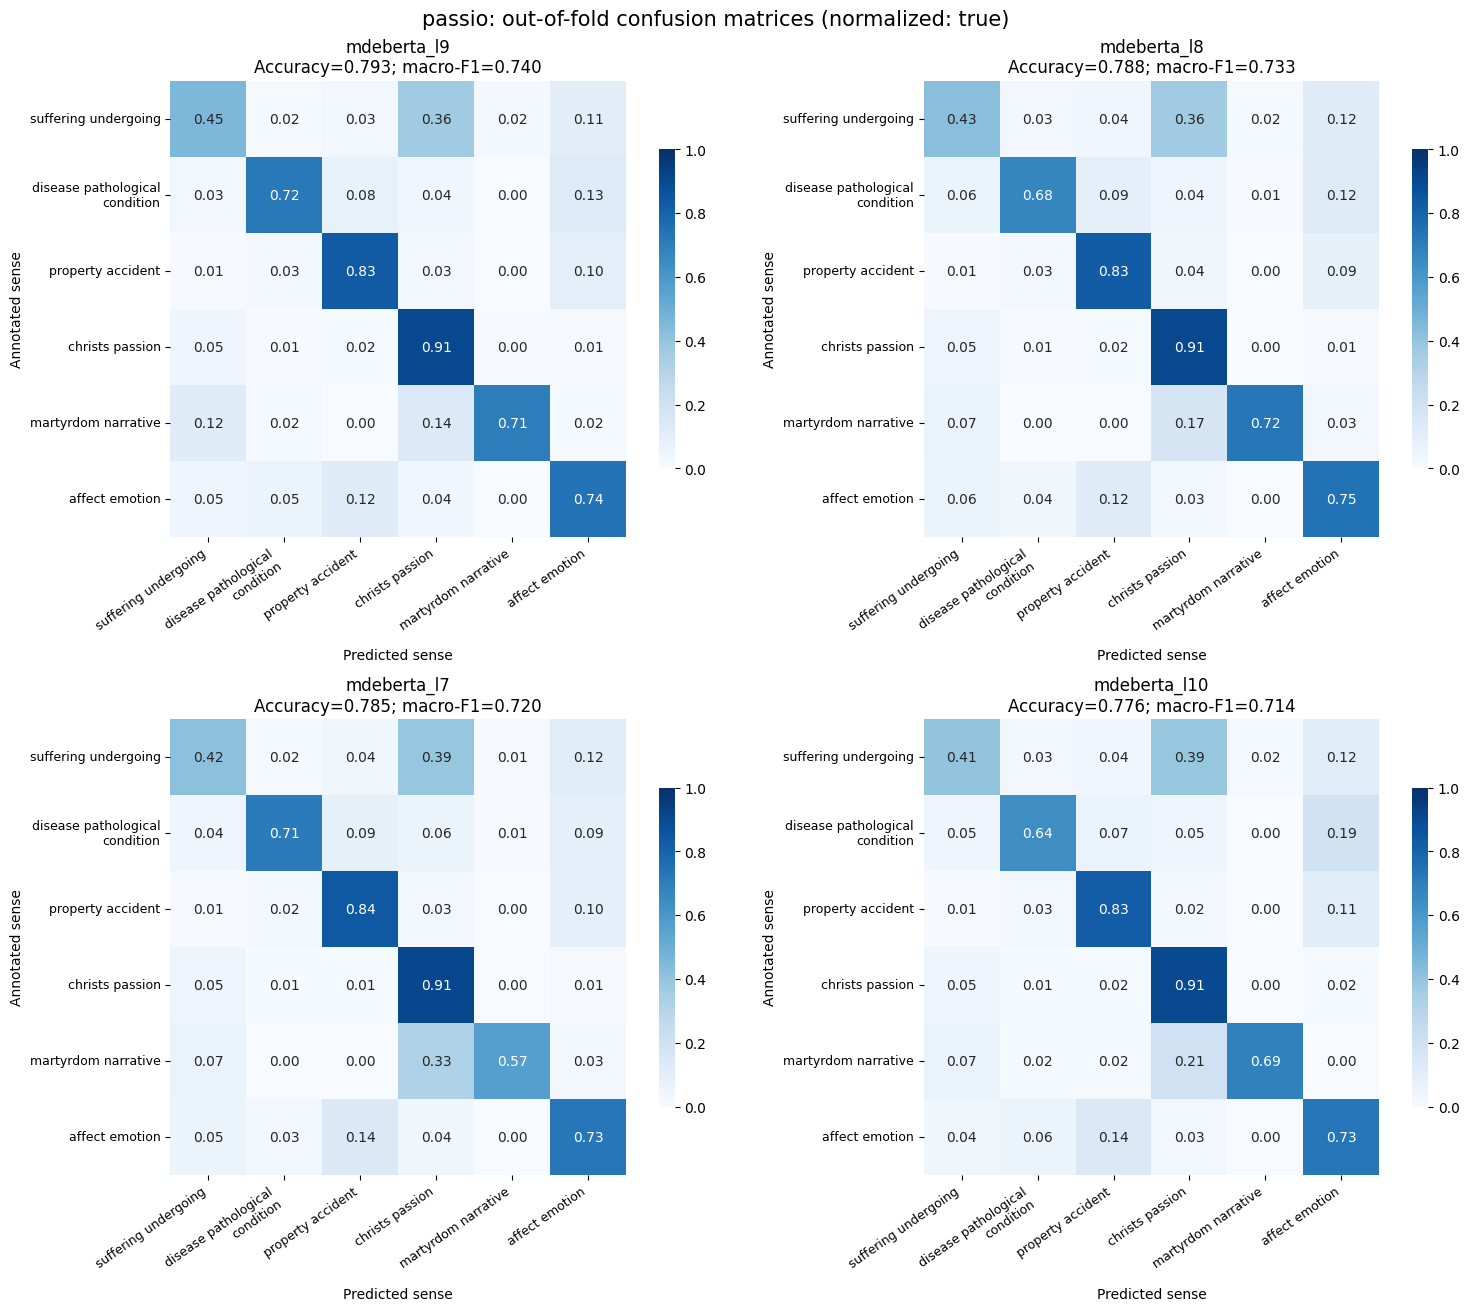

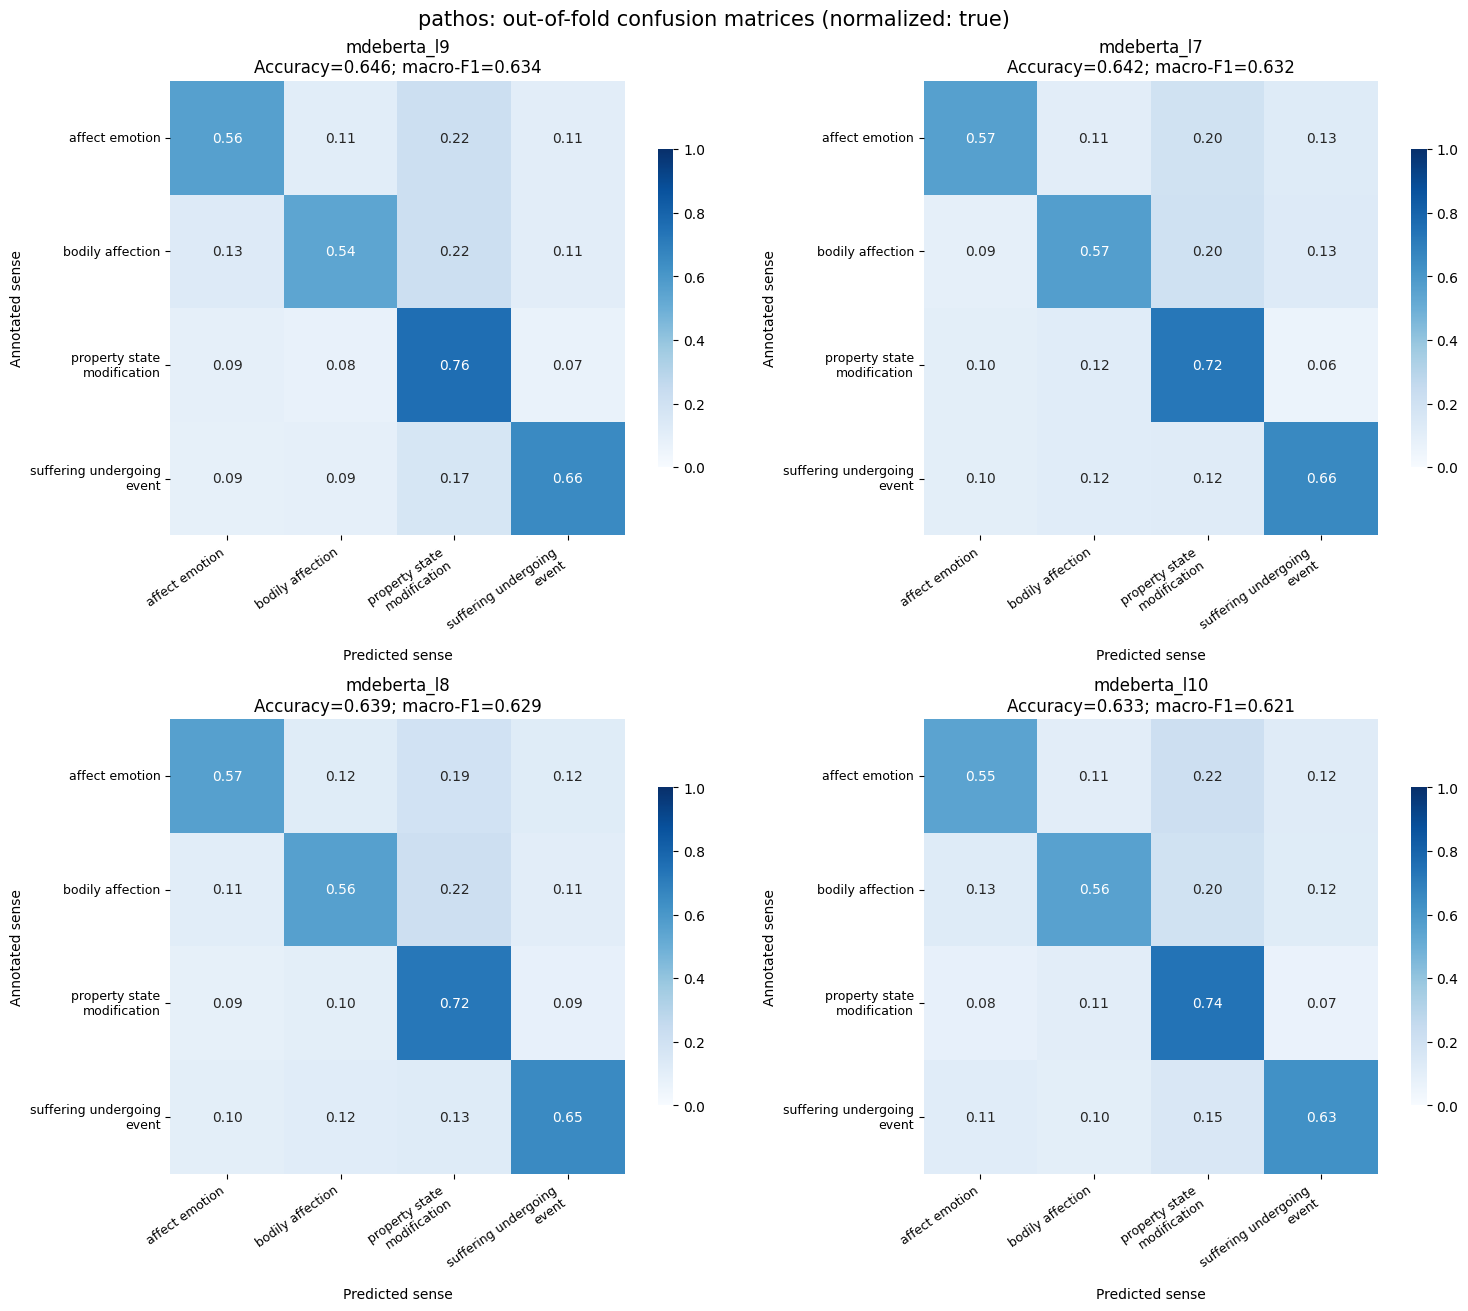

In [91]:
# Change TOP_N to None to plot all evaluated embeddings.
# Or pass embedding_cols=["emb_mdeberta_l7", "emb_mdeberta_l11"] to compare layers.
CM_TOP_N = 4
CM_NORMALIZE = "true"  # row proportions; use None for counts

confusion_figures = {}
confusion_matrices = {}
for lexeme, df, results in [
    ("passio", passio_df, passio_results),
    ("pathos", pathos_df, pathos_results),
]:
    fig_cm, axes_cm, matrices_cm = plot_embedding_confusion_matrices(
        df, results, lexeme, label_col=LABEL_COL,
        top_n=CM_TOP_N, normalize=CM_NORMALIZE,
    )
    confusion_figures[lexeme] = fig_cm
    confusion_matrices[lexeme] = matrices_cm
    fig_cm.savefig(f"../figures/{lexeme}-embedding-confusion-matrices.png",
                   dpi=300, bbox_inches="tight")
    plt.show()


passio: accuracy=0.8100, macro-F1=0.7568


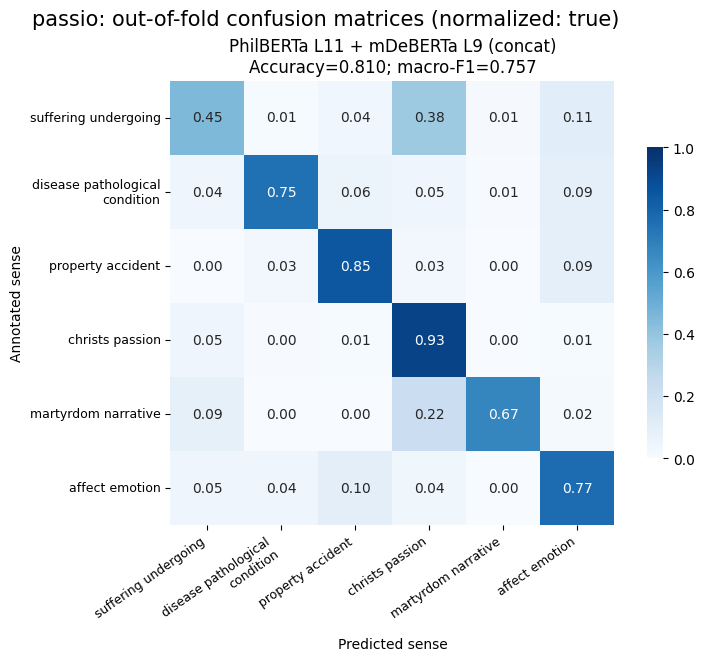

pathos: accuracy=0.6970, macro-F1=0.6853


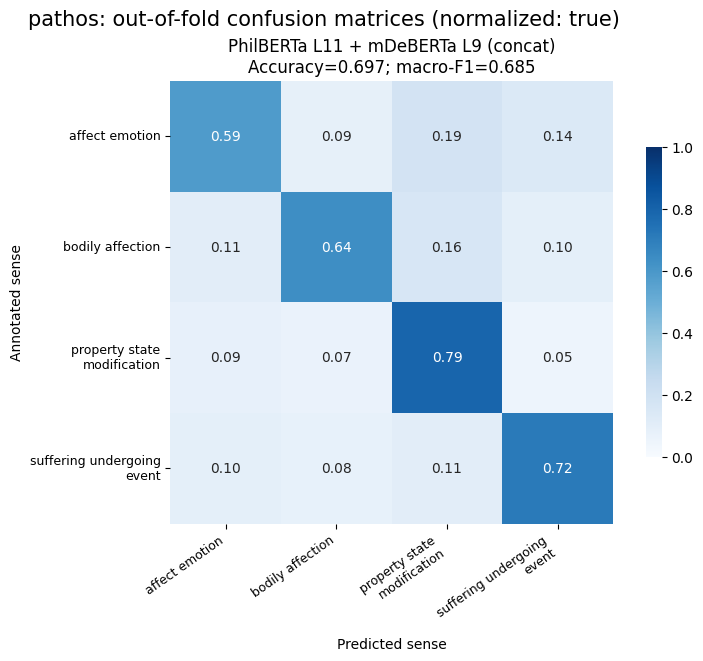

In [92]:
CONCAT_COLS = ["emb_philberta_l11", "emb_mdeberta_l9"]
CONCAT_NAME = "PhilBERTa L11 + mDeBERTa L9 (concat)"

concat_results = {}
concat_figures = {}

for lexeme, df in [
    ("passio", passio_df),
    ("pathos", pathos_df),
]:
    X_concat = classification_helpers.merge_multiple_embeddings(
        df, CONCAT_COLS, method="concat"
    )

    # Match the label encoding used by the existing evaluation helper.
    _, y_concat = classification_helpers.prepare_classification_data(
        df, CONCAT_COLS[0], LABEL_COL
    )

    clf = classification_helpers.create_mlp_classifier()
    result = classification_helpers.evaluate_classifier(
        X_concat, y_concat, clf, cv=5
    )
    concat_results[lexeme] = result

    print(
        f"{lexeme}: accuracy={result['accuracy']:.4f}, "
        f"macro-F1={result['f1_macro']:.4f}"
    )

    fig, axes, matrices = plot_embedding_confusion_matrices(
        df=df,
        results={CONCAT_NAME: result},
        lexeme=lexeme,
        label_col=LABEL_COL,
        embedding_cols=[CONCAT_NAME],
        normalize="true",  # Use None for raw counts.
        ncols=1,
    )
    concat_figures[lexeme] = fig

    fig.savefig(
        f"../figures/{lexeme}-philberta-l11-mdeberta-l9-concat-confusion.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

passio: accuracy=0.8100, macro-F1=0.7568
pathos: accuracy=0.6970, macro-F1=0.6853


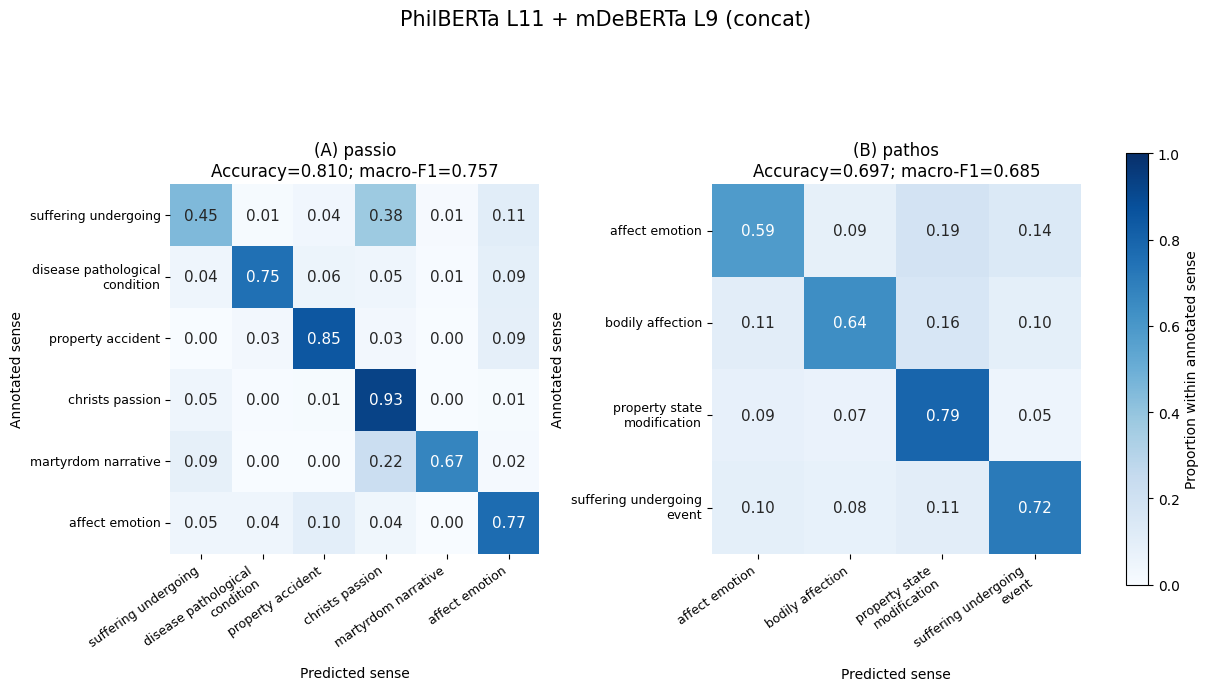

In [97]:
import importlib
import textwrap
from pathlib import Path

CONCAT_COLS = ["emb_philberta_l11", "emb_mdeberta_l9"]
CONCAT_NAME = "PhilBERTa L11 + mDeBERTa L9 (concat)"

concat_results = {}
concat_matrices = {}

fig, axes = plt.subplots(
    1, 2, figsize=(12,7), constrained_layout=True
)

for panel, ax, lexeme, df in [
    ("A", axes[0], "passio", passio_df),
    ("B", axes[1], "pathos", pathos_df),
]:
    X_concat = classification_helpers.merge_multiple_embeddings(
        df, CONCAT_COLS, method="concat"
    )
    _, y_concat = classification_helpers.prepare_classification_data(
        df, CONCAT_COLS[0], LABEL_COL
    )

    result = classification_helpers.evaluate_classifier(
        X_concat, y_concat,
        classification_helpers.create_mlp_classifier(),
        cv=5,
    )
    concat_results[lexeme] = result

    # Reload the current sense inventory.
    prompt_module = importlib.import_module(f"llmprompt_{lexeme}")
    label_map = dict(importlib.reload(prompt_module).LABEL_MAP)

    def sense_name(label):
        key = int(label) if isinstance(label, str) and label.isdigit() else label
        return str(label_map.get(key, label))

    # Account for first-seen encoding of object-dtype labels.
    original_labels = df[LABEL_COL].unique()
    if df[LABEL_COL].dtype == object:
        display_map = {
            i: sense_name(label)
            for i, label in enumerate(original_labels)
        }
    else:
        display_map = {
            label: sense_name(label) for label in original_labels
        }

    labels = sorted(np.unique(y_concat))
    names = [
        textwrap.fill(display_map[label].replace("_", " "), width=22)
        for label in labels
    ]

    cm = confusion_matrix(
        y_concat, result["predictions"],
        labels=labels, normalize="true",
    )
    concat_matrices[lexeme] = cm

    sns.heatmap(
        cm, annot=True, fmt=".2f", cmap="Blues",
        vmin=0, vmax=1, square=True, cbar=False,
        xticklabels=names, yticklabels=names, ax=ax,
        annot_kws={"fontsize": 11},
    )

    word = "pathos" if lexeme == "pathos" else "passio"
    ax.set_title(
        f"({panel}) {word}\n"
        f"Accuracy={result['accuracy']:.3f}; "
        f"macro-F1={result['f1_macro']:.3f}"
    )
    ax.set_xlabel("Predicted sense")
    ax.set_ylabel("Annotated sense")
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right", fontsize=9)
    plt.setp(ax.get_yticklabels(), rotation=0, fontsize=9)

    print(
        f"{lexeme}: accuracy={result['accuracy']:.4f}, "
        f"macro-F1={result['f1_macro']:.4f}"
    )

fig.suptitle(CONCAT_NAME, fontsize=15)
fig.colorbar(
    axes[0].collections[0], ax=axes,
    shrink=0.65, label="Proportion within annotated sense",
)

output = Path("../figures/passio-pathos-concat-confusion-matrices")
fig.savefig(output.with_suffix(".png"), dpi=300, bbox_inches="tight")
fig.savefig(output.with_suffix(".pdf"), bbox_inches="tight")
plt.show()